<a href="https://colab.research.google.com/github/sociallyH03ly/PH-Political-Parties-and-Candidates-Analysis/blob/main/PH_Political_Party_and_Candidates_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Loading and Inspecting the Parquet Dataset

In [8]:
import pandas as pd

# Load the uploaded Parquet file
df_parquet = pd.read_parquet('/content/0000.parquet')

# Print fundamental structure details
print(f"Dataset Shape: {df_parquet.shape}")
print("\nDataset Columns and Types:")
print(df_parquet.info())

# Preview the first few records
display(df_parquet.head())

Dataset Shape: (86234, 8)

Dataset Columns and Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86234 entries, 0 to 86233
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         86234 non-null  object
 1   person_id  86234 non-null  object
 2   party      86234 non-null  object
 3   region     86234 non-null  object
 4   province   86234 non-null  object
 5   locality   58594 non-null  object
 6   position   86234 non-null  object
 7   year       86234 non-null  int32 
dtypes: int32(1), object(7)
memory usage: 4.9+ MB
None


,id,person_id,party,region,province,locality,position,year
0,01K7QAQB1SY5XFF0N3Y7S168NF_m0,01K7QAQB1SY5XFF0N3Y7S168NF,LKS-KAM,NATIONAL CAPITAL REGION,"NCR, SECOND DISTRICT",CITY OF MANDALUYONG,COUNCILOR,2010
1,01K7QAQB1SY5XFF0N3Y7S168NF_m1,01K7QAQB1SY5XFF0N3Y7S168NF,LP,NATIONAL CAPITAL REGION,"NCR, SECOND DISTRICT",None,COUNCILOR,2013
2,01K7QAQB1SY5XFF0N3Y7S168NF_m2,01K7QAQB1SY5XFF0N3Y7S168NF,LP,NATIONAL CAPITAL REGION,"NCR, SECOND DISTRICT",None,COUNCILOR,2016
3,01K7QAQB6TJ4YRM2C53RQZT9V9_m0,01K7QAQB6TJ4YRM2C53RQZT9V9,NP,REGION XII,SARANGANI,None,COUNCILOR,2013
4,01K7QAQB6TJ4YRM2C53RQZT9V9_m1,01K7QAQB6TJ4YRM2C53RQZT9V9,PMP,REGION XII,SARANGANI,MAITUM,COUNCILOR,2010


### Step 1: Data Cleaning

In [9]:
# Make a copy for cleaning
cleaned_parquet = df_parquet.copy()

# Standardize text format (uppercase and stripped of trailing whitespace)
string_cols = ['party', 'region', 'province', 'locality', 'position']
for col in string_cols:
    cleaned_parquet[col] = cleaned_parquet[col].astype(str).str.strip().str.upper()

# Replace 'NONE' or 'NAN' (resulting from previous None values converted to string) with proper category
cleaned_parquet['locality'] = cleaned_parquet['locality'].replace({'NONE': 'PROVINCIAL LEVEL/NOT SPECIFIED', 'NAN': 'PROVINCIAL LEVEL/NOT SPECIFIED'})

# Drop exact duplicate rows if any exist
duplicates_count = cleaned_parquet.duplicated().sum()
if duplicates_count > 0:
    print(f"Removing {duplicates_count} exact duplicates...")
    cleaned_parquet = cleaned_parquet.drop_duplicates()
else:
    print("No exact duplicates found.")

print("Cleaned dataset summary:")
print(cleaned_parquet.info())
display(cleaned_parquet.head())

No exact duplicates found.
Cleaned dataset summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86234 entries, 0 to 86233
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         86234 non-null  object
 1   person_id  86234 non-null  object
 2   party      86234 non-null  object
 3   region     86234 non-null  object
 4   province   86234 non-null  object
 5   locality   86234 non-null  object
 6   position   86234 non-null  object
 7   year       86234 non-null  int32 
dtypes: int32(1), object(7)
memory usage: 4.9+ MB
None


,id,person_id,party,region,province,locality,position,year
0,01K7QAQB1SY5XFF0N3Y7S168NF_m0,01K7QAQB1SY5XFF0N3Y7S168NF,LKS-KAM,NATIONAL CAPITAL REGION,"NCR, SECOND DISTRICT",CITY OF MANDALUYONG,COUNCILOR,2010
1,01K7QAQB1SY5XFF0N3Y7S168NF_m1,01K7QAQB1SY5XFF0N3Y7S168NF,LP,NATIONAL CAPITAL REGION,"NCR, SECOND DISTRICT",PROVINCIAL LEVEL/NOT SPECIFIED,COUNCILOR,2013
2,01K7QAQB1SY5XFF0N3Y7S168NF_m2,01K7QAQB1SY5XFF0N3Y7S168NF,LP,NATIONAL CAPITAL REGION,"NCR, SECOND DISTRICT",PROVINCIAL LEVEL/NOT SPECIFIED,COUNCILOR,2016
3,01K7QAQB6TJ4YRM2C53RQZT9V9_m0,01K7QAQB6TJ4YRM2C53RQZT9V9,NP,REGION XII,SARANGANI,PROVINCIAL LEVEL/NOT SPECIFIED,COUNCILOR,2013
4,01K7QAQB6TJ4YRM2C53RQZT9V9_m1,01K7QAQB6TJ4YRM2C53RQZT9V9,PMP,REGION XII,SARANGANI,MAITUM,COUNCILOR,2010


### Step 2: Analysis - Top Parties and Regional Distribution

Top 10 Political Parties:
party
LP             18666
LAKAS-CMD      13451
NPC             9986
LKS-KAM         7435
NP              5863
KAMPI           4316
IND             4249
INDEPENDENT     3118
UNA             2636
NUP             2512
Name: count, dtype: int64


/tmp/ipykernel_579/709018454.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_parties.values, y=top_parties.index, palette='coolwarm')


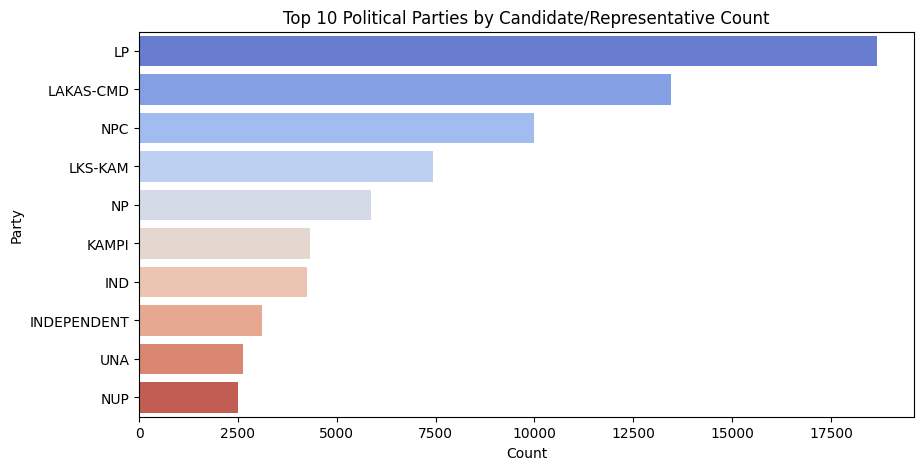


Distribution of Political Positions:
position
COUNCILOR                           64792
MAYOR                                7901
VICE MAYOR                           7882
PROVINCIAL BOARD MEMBER              3747
MEMBER, HOUSE OF REPRESENTATIVES     1121
GOVERNOR                              397
VICE GOVERNOR                         394
Name: count, dtype: int64


/tmp/ipykernel_579/709018454.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=position_counts.values, y=position_counts.index, palette='viridis')


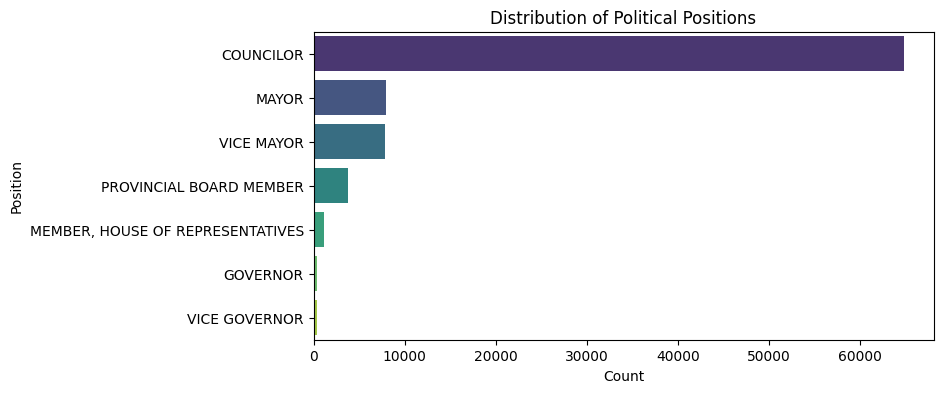

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Top Political Parties
top_parties = cleaned_parquet['party'].value_counts().head(10)
print("Top 10 Political Parties:")
print(top_parties)

# Plot top political parties
plt.figure(figsize=(10, 5))
sns.barplot(x=top_parties.values, y=top_parties.index, palette='coolwarm')
plt.title('Top 10 Political Parties by Candidate/Representative Count')
plt.xlabel('Count')
plt.ylabel('Party')
plt.show()

# 2. Distribution of Political Positions
position_counts = cleaned_parquet['position'].value_counts()
print("\nDistribution of Political Positions:")
print(position_counts)

# Plot positions
plt.figure(figsize=(8, 4))
sns.barplot(x=position_counts.values, y=position_counts.index, palette='viridis')
plt.title('Distribution of Political Positions')
plt.xlabel('Count')
plt.ylabel('Position')
plt.show()

### Step 3: Candidate Distribution by Region
We will now calculate the total number of candidates (records) for each region and visualize this distribution.

Candidates per Region:
region
REGION VIII                             7438
REGION IV-A                             7411
REGION VI                               7086
REGION III                              6966
REGION VII                              6936
REGION I                                6521
REGION V                                6042
AUTONOMOUS REGION IN MUSLIM MINDANAO    5076
REGION X                                4983
REGION II                               4933
CORDILLERA ADMINISTRATIVE REGION        4165
REGION XIII                             3927
REGION IV-B                             3870
REGION IX                               3709
REGION XI                               2832
REGION XII                              2712
NATIONAL CAPITAL REGION                 1627
Name: count, dtype: int64


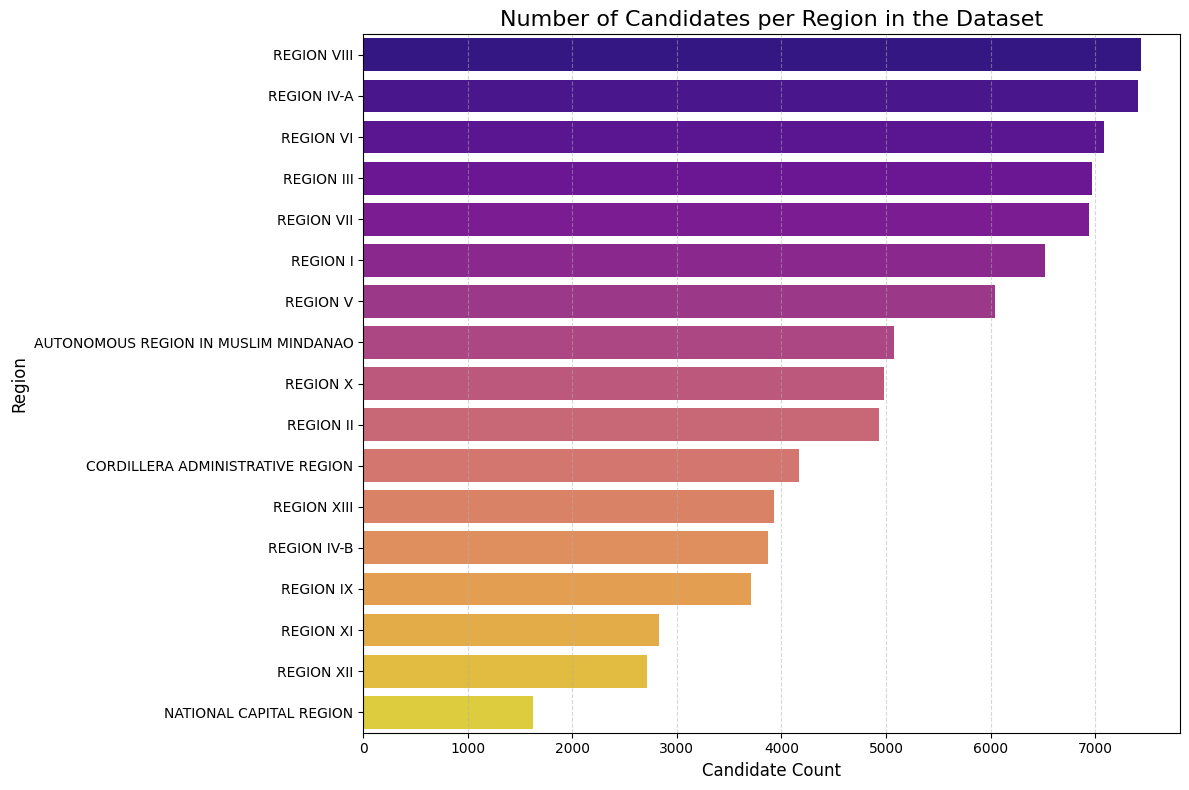

In [11]:
# Calculate the number of candidates per region
region_counts = cleaned_parquet['region'].value_counts()
print("Candidates per Region:")
print(region_counts)

# Plot the candidate counts per region
plt.figure(figsize=(12, 8))
sns.barplot(x=region_counts.values, y=region_counts.index, palette='plasma', hue=region_counts.index, legend=False)
plt.title('Number of Candidates per Region in the Dataset', fontsize=16)
plt.xlabel('Candidate Count', fontsize=12)
plt.ylabel('Region', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Step 4: Combined Distribution of Candidates by Party and Region

Cross-tabulation (Top 10 Parties vs Regions):


party,IND,INDEPENDENT,KAMPI,LAKAS-CMD,LKS-KAM,LP,NP,NPC,NUP,UNA
region,,,,,,,,,,
REGION VIII,308,166,314,1094,882,2222,376,738,444,140
REGION IV-A,203,153,455,876,505,2192,511,698,371,442
REGION VI,263,177,300,1079,574,2008,285,736,265,223
REGION III,291,169,356,952,443,1057,223,855,293,146
REGION VII,251,306,348,1309,623,1484,374,621,103,175
REGION I,322,246,237,1103,543,1011,674,1316,9,136
REGION V,215,156,293,1049,498,1173,556,1087,143,242
AUTONOMOUS REGION IN MUSLIM MINDANAO,466,313,199,957,389,1357,72,216,20,142
REGION X,213,142,274,1174,537,779,445,228,134,91


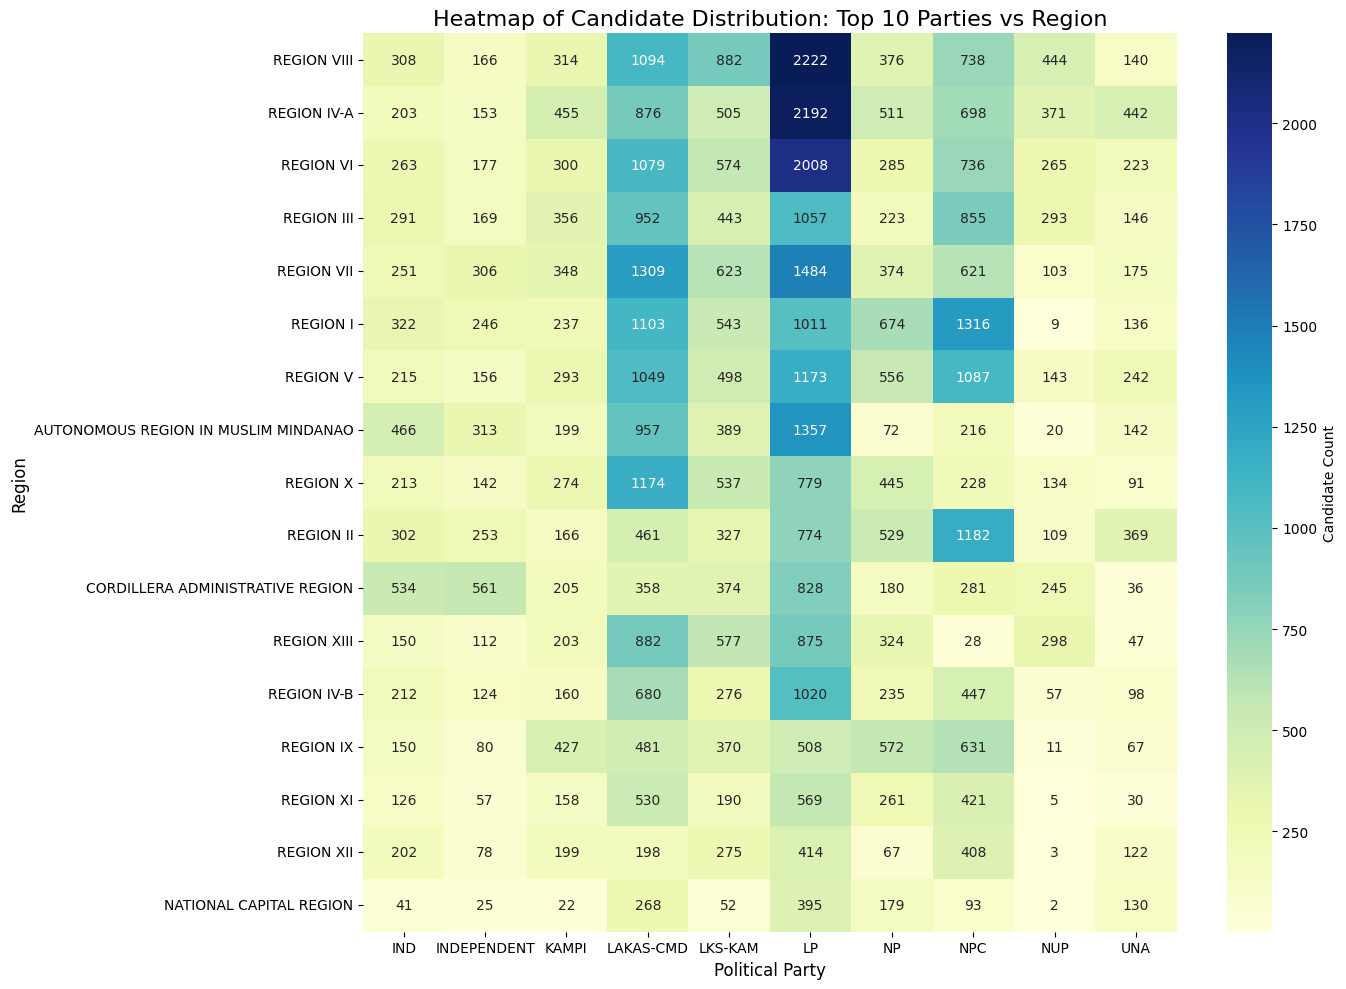

In [12]:
# Identify the top 10 political parties
top_10_parties = cleaned_parquet['party'].value_counts().head(10).index

# Filter the dataset to include only these top parties
filtered_df = cleaned_parquet[cleaned_parquet['party'].isin(top_10_parties)]

# Create a pivot table/cross-tabulation of Party vs Region
party_region_pivot = pd.crosstab(filtered_df['region'], filtered_df['party'])

# Sort regions by total candidates to match our previous regional analysis ordering
party_region_pivot = party_region_pivot.reindex(region_counts.index)

# Display the raw pivot table values
print("Cross-tabulation (Top 10 Parties vs Regions):")
display(party_region_pivot)

# Plot the distribution as a heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(party_region_pivot, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={'label': 'Candidate Count'})
plt.title('Heatmap of Candidate Distribution: Top 10 Parties vs Region', fontsize=16)
plt.xlabel('Political Party', fontsize=12)
plt.ylabel('Region', fontsize=12)
plt.tight_layout()
plt.show()

### Step 5: Deep Dive - Political Trends Over Time
Analyzing how the participation of the top political parties has shifted across the different years.

Top Parties Over the Years:


party,IND,INDEPENDENT,KAMPI,LAKAS-CMD,LKS-KAM,LP,NP,NPC,NUP,UNA
year,,,,,,,,,,
2004,0,1842,206,7353,0,1400,5,2528,0,13
2007,0,1276,4088,6098,0,1119,156,1722,0,0
2010,0,0,22,0,7435,2542,2579,1395,0,24
2013,2108,0,0,0,0,6300,1720,2248,1267,1087
2016,2141,0,0,0,0,7305,1403,2093,1245,1512


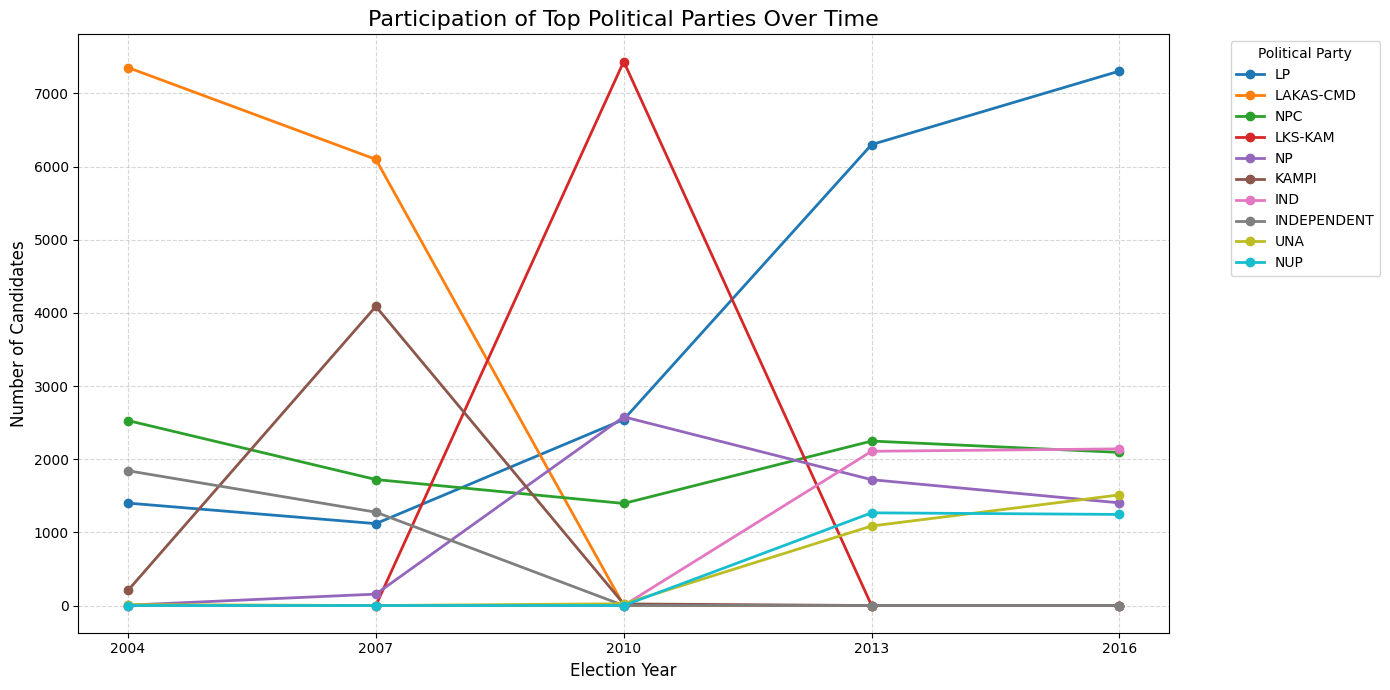

In [13]:
# Calculate party counts by year
party_year_df = cleaned_parquet[cleaned_parquet['party'].isin(top_10_parties)]
party_year_pivot = pd.crosstab(party_year_df['year'], party_year_df['party'])

# Display the table
print("Top Parties Over the Years:")
display(party_year_pivot)

# Plot the temporal trend
plt.figure(figsize=(14, 7))
for party in top_10_parties:
    if party in party_year_pivot.columns:
        plt.plot(party_year_pivot.index, party_year_pivot[party], marker='o', label=party, linewidth=2)

plt.title('Participation of Top Political Parties Over Time', fontsize=16)
plt.xlabel('Election Year', fontsize=12)
plt.ylabel('Number of Candidates', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(party_year_pivot.index)
plt.legend(title='Political Party', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Step 6: Market Share of Parties per Region
Uncovering regions where a specific party holds a dominant local share by converting absolute numbers to percentages

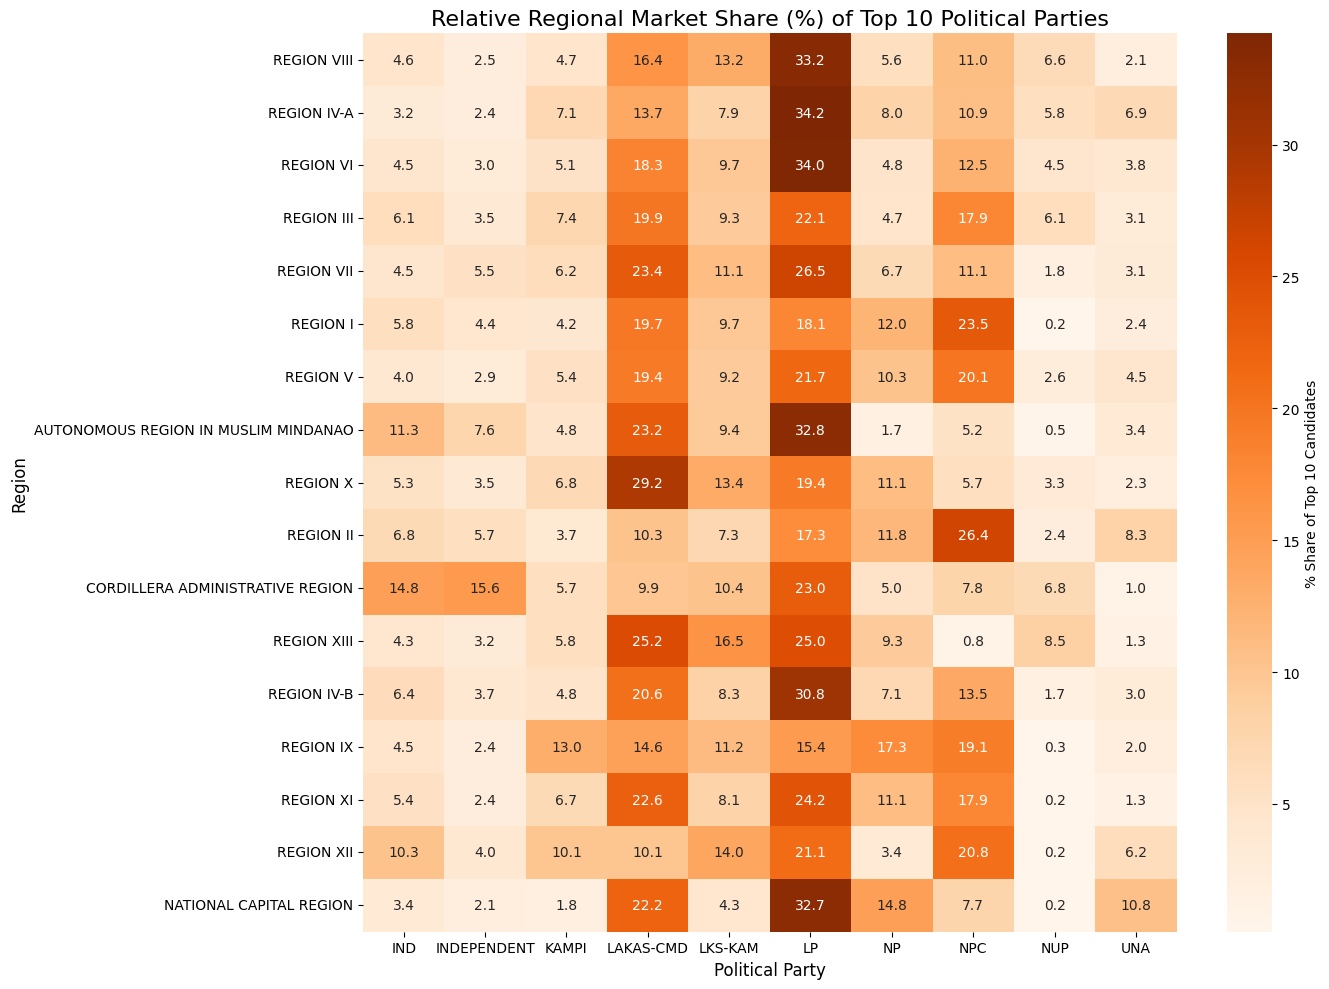

In [14]:
# Calculate regional market share (% of candidates in that region belonging to each party)
regional_shares = party_region_pivot.div(party_region_pivot.sum(axis=1), axis=0) * 100

# Plot the relative market shares
plt.figure(figsize=(14, 10))
sns.heatmap(regional_shares, annot=True, fmt=".1f", cmap="Oranges", cbar_kws={'label': '% Share of Top 10 Candidates'})
plt.title('Relative Regional Market Share (%) of Top 10 Political Parties', fontsize=16)
plt.xlabel('Political Party', fontsize=12)
plt.ylabel('Region', fontsize=12)
plt.tight_layout()
plt.show()

### Step 7: Analyzing Independent Candidates Over Time

Independent Candidates Count by Region and Year:


year,2004,2007,2013,2016
region,,,,
AUTONOMOUS REGION IN MUSLIM MINDANAO,195,118,243,223
CORDILLERA ADMINISTRATIVE REGION,286,275,285,249
NATIONAL CAPITAL REGION,15,10,13,28
REGION I,144,102,154,168
REGION II,156,97,183,119
REGION III,110,59,118,173
REGION IV-A,88,65,86,117
REGION IV-B,75,49,89,123
REGION IX,41,39,30,120



Regions sorted by increase of Independent Candidates from 2013 to 2016:


year,change_2013_to_2016
region,
REGION IX,90
REGION III,55
REGION IV-B,34
REGION IV-A,31
REGION V,21
REGION VII,19
NATIONAL CAPITAL REGION,15
REGION I,14
REGION VI,5


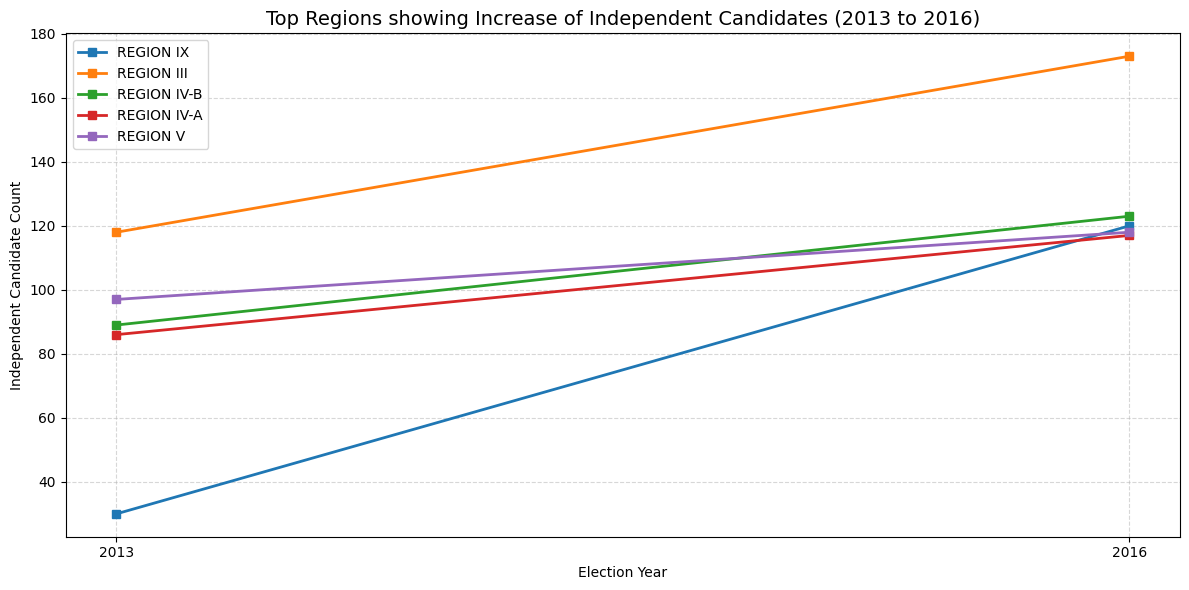

In [15]:
# Filter for independent candidates
independents = cleaned_parquet[cleaned_parquet['party'].isin(['IND', 'INDEPENDENT'])]

# Create a pivot table: Regions vs Years
ind_pivot = pd.crosstab(independents['region'], independents['year'])
print("Independent Candidates Count by Region and Year:")
display(ind_pivot)

# Calculate change from earliest available year in active recording to latest (2013 to 2016 for 'IND')
# Since 'INDEPENDENT' was recorded in 2004-2007 and 'IND' in 2013-2016, let's look at the absolute change between 2013 and 2016
ind_pivot['change_2013_to_2016'] = ind_pivot[2016] - ind_pivot[2013]
sorted_increase = ind_pivot.sort_values(by='change_2013_to_2016', ascending=False)

print("\nRegions sorted by increase of Independent Candidates from 2013 to 2016:")
display(sorted_increase[['change_2013_to_2016']])

# Plot the trends of top regions showing an increase
top_increasing_regions = sorted_increase.head(5).index

plt.figure(figsize=(12, 6))
for region in top_increasing_regions:
    # We plot 2013 and 2016 since IND was actively used there
    years = [2013, 2016]
    values = [ind_pivot.loc[region, 2013], ind_pivot.loc[region, 2016]]
    plt.plot(years, values, marker='s', label=region, linewidth=2)

plt.title('Top Regions showing Increase of Independent Candidates (2013 to 2016)', fontsize=14)
plt.xlabel('Election Year')
plt.ylabel('Independent Candidate Count')
plt.xticks([2013, 2016])
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## Philippines' Political Parties and Candidates Analysis Report

This analysis provides an exhaustive synthesis of the analytical steps, dataset treatment, and multidimensional trends uncovered from the historical database of **86,234 Philippine candidate records** spanning election years **2004 to 2016**.

---

### 1. Data Cleaning & Integrity Actions
Prior to performing the analysis, the dataset underwent strict preprocessing to ensure reporting accuracy:
* **Standardization**: All text features (`party`, `region`, `province`, `locality`, `position`) were stripped of leading/trailing whitespaces and converted to uniform uppercase format.
* **Handling Missing Data**: Missing values within the `locality` column (representing approximately **32%** of the dataset) were standardly classified as `PROVINCIAL LEVEL/NOT SPECIFIED` to prevent omission bias during spatial profiling.
* **De-duplication**: The dataset was verified to have no exact duplicate rows, confirming a clean, high-fidelity relational schema.

---

### 2. Structural & Distributional Insights

#### A. Positional Profile
Local governance positions form the vast majority of the electoral field, indicating a bottom-heavy representative hierarchy:
* **Councilors**: Make up **75.1%** of all candidate entries ($64,792$ records).
* **Mayoral and Vice-Mayoral Positions**: Comprise **9.1%** ($7,901$) and **9.1%** ($7,882$) respectively.
* **Provincial Board Members**: Account for **4.3%** ($3,747$).
* **Higher Executive Positions** (Governors, Vice Governors, and House of Representative Members) make up the remaining **2.3%** of the dataset.

#### B. Geographic Volume
Electoral competitiveness is concentrated in key geographic corridors:
* **High-Volume Centers**: **Region VIII (Eastern Visayas)** and **Region IV-A (Calabarzon)** lead candidate listings with **7,438** and **7,411** records respectively.
* **Low-Volume Centers**: **National Capital Region (NCR)** exhibits the lowest total count with only **1,627** records, reflecting concentrated city-level districts compared to sprawling municipal structures in rural regions.

---

### 3. Deep-Dive Political Dynamics & Trends

#### A. Temporal Coalition Shifts & Volatility
The trajectory of major political parties highlights a volatile, coalition-driven ecosystem closely aligned with national administrative transitions:
* **Lakas-CMD** held absolute dominance in 2004 with **7,353 candidates** but dropped sharply over the next decade, virtually vanishing from independent party lines by 2010 during structural reorganizations.
* **LKS-KAM** spiked to **7,435 candidates** in 2010, serving as a transitional vehicle, but collapsed to zero by 2013.
* **The Liberal Party (LP)** demonstrated the most robust growth curve, rising from a modest **1,400 candidates in 2004** to a commanding peak of **7,305 candidates in 2016**.

#### B. Regional Strongholds (Market Share %)
When normalizing regional numbers to party market shares, distinct regional fortress patterns emerge:
* **Liberal Party (LP)**: Reached its highest territorial dominance in **Region IV-A (34.2%)**, **Region VI (34.0%)**, and **Region VIII (33.2%)**.
* **Nationalist People's Coalition (NPC)**: Retains strong local bases in non-metropolitan areas, commanding **26.4% of Region II** and **23.5% of Region I**.
* **The Independent Phenomenon**: The **Cordillera Administrative Region (CAR)** presents an atypical political layout. Independent candidates (labeled `IND` and `INDEPENDENT`) hold a massive combined local market share of **30.4%** (14.8% and 15.6% respectively). This indicates that localized clan alignments and local dynamics frequently overshadow traditional national party machinery in this mountainous region.

#### C. Rise of Non-Partisan Candidates (2013 vs 2016)
By tracking the growth rate of independent filings (`IND`) during the later stage of the dataset:
* **Region IX (Zamboanga Peninsula)** experienced the most intense expansion of independent representation, surging by **+90 candidates** (from 30 in 2013 to 120 in 2016).
* **Region III (Central Luzon)** followed with an increase of **+55 candidates** (from 118 in 2013 to 173 in 2016).
* Conversely, traditional party frameworks consolidated their control in regions like **Region VIII** and **Region II**, where independent numbers declined by **-64 candidates** in each area, pointing to a strengthening of formal party networks.